# Create DTW based classifier

In [7]:
CUT_PARAMS = {
    'signal_name': 'wideband',
    'event_name': 'spk',
    'cut_window': [-0.001, 0.002],
    'fs': 40000
}
SMOOTH_PARAMS = {
    'window_length': 9,
    'polyorder': 3
}
PROCESS_PARAMS = {
    'smooth_params': SMOOTH_PARAMS,
    'dv_threshold': 0.1
}

In [8]:
import os

INVITRO_DATA_DIR = f'{os.environ["RAAP_INVITRO_DATA"]}/juxta'
INVIVO_DATA_DIR = f'{os.environ["RAAP_INVIVO_DATA"]}'
INVIVO_FEATURE_DIR = f'{os.environ["RAAP_INVIVO_FEATURES"]}'

In [9]:
training_cell_names = [
    '2406241PZ_01',
    '2406242PZ_03',
    '2406263PZ_01',
    '2406282PZ_01',
    '2407031PZ_01',
    '2407031SI_gr2',
    '2407041SI_gr1'
]

In [10]:
from classifiy_spikes_using_dtw import load_training_data
training_data = load_training_data(
    training_cell_names,
    INVITRO_DATA_DIR,
    cut_params=CUT_PARAMS,
    proc_params=PROCESS_PARAMS
)

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from classifiy_spikes_using_dtw import mean_shapes_rising

cell_means = []
for i, cell_shapes in enumerate(training_data):
    cell_means.append((
        mean_shapes_rising(
            cell_shapes[0], start_ratio=0.15, end_ratio=0.85
        ),
        mean_shapes_rising(
            cell_shapes[1], start_ratio=0.15, end_ratio=0.85
        )
    ))


c:\Projects\RaAp\notebooks\classifiy_spikes_using_dtw.py:93: RuntimeWarning: Mean of empty slice
  mean_v = np.nanmean(np.stack([s.values for s in rising_shapes], axis=0), axis=0)


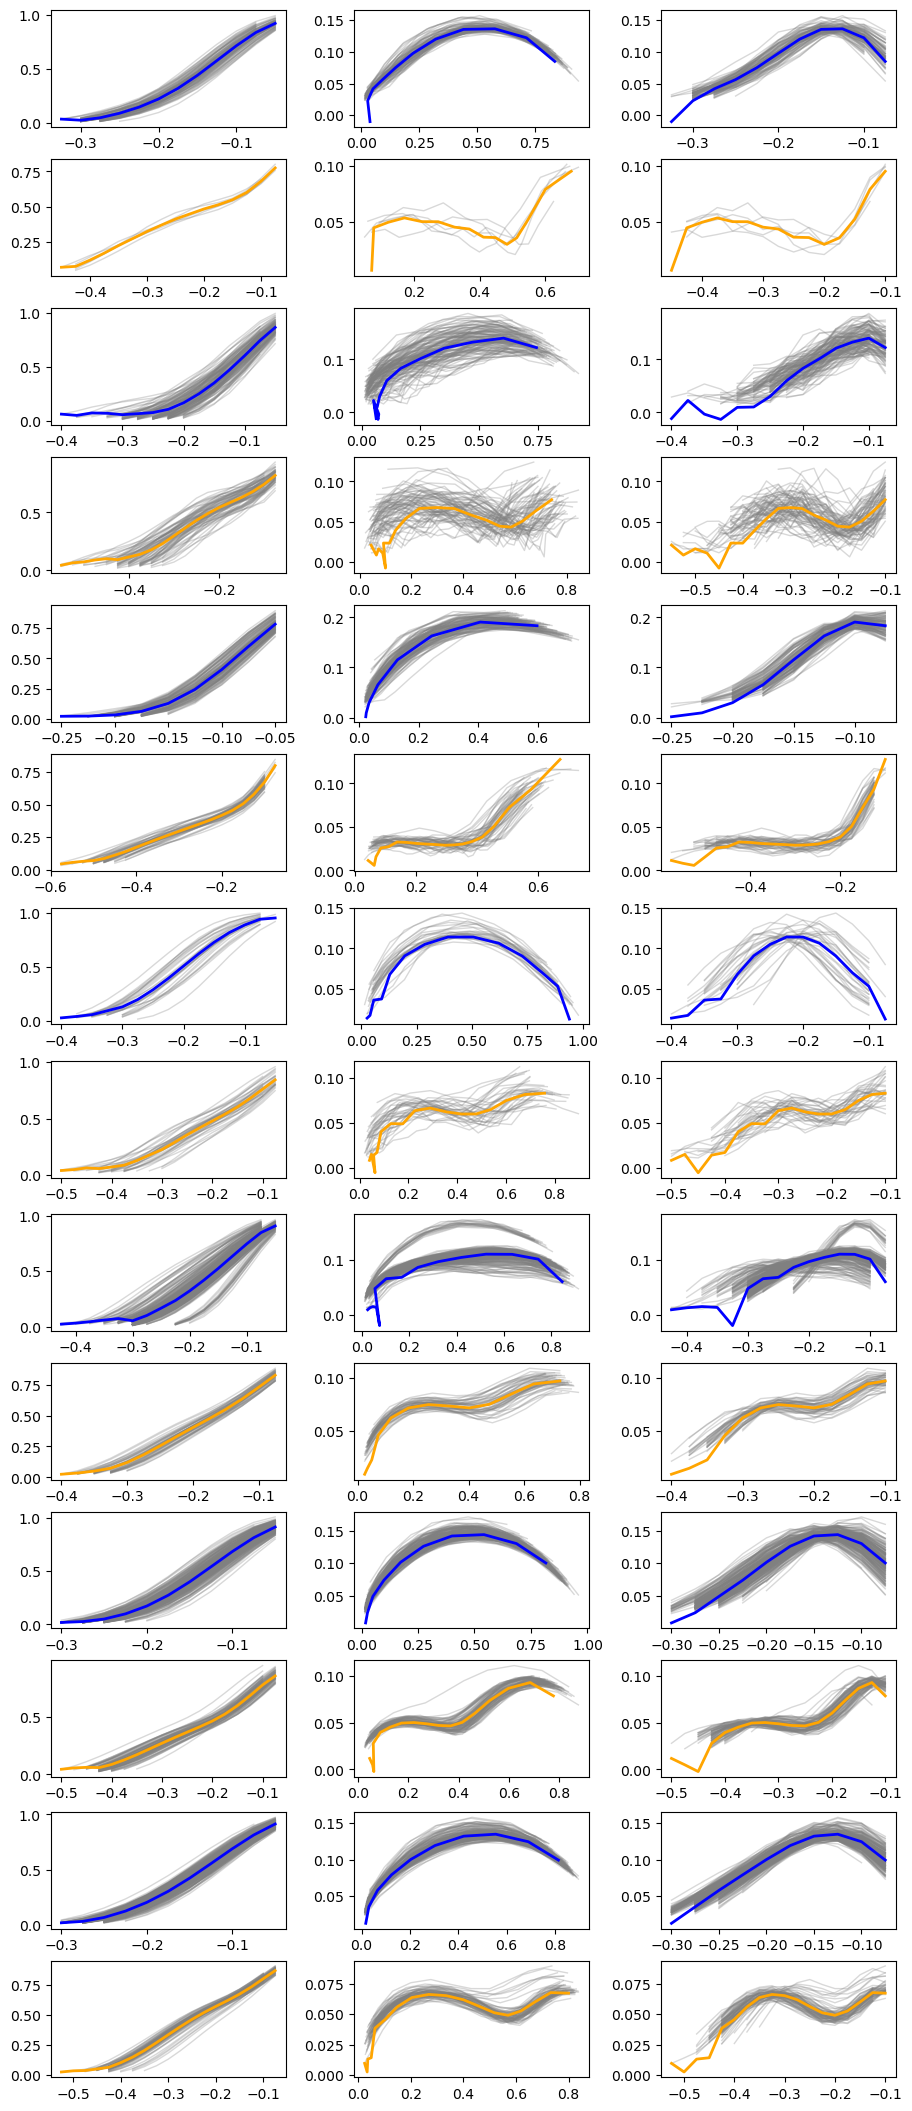

In [12]:
from notebooks.classifiy_spikes_using_dtw import get_rising_phase


fig, axes = plt.subplots(
    len(training_data) * 2, 3,
    figsize=(9, 3 * len(training_data)),
    layout='constrained'
)
for i, proc_shapes in enumerate(training_data):
    for j, (shapes, color) in enumerate(zip(proc_shapes, ['blue', 'orange'])):
        rising_shapes = [
             get_rising_phase(s, 0.15, 0.85, keep_size=True)
             for s in shapes
        ]
        for shape in rising_shapes:
            ax = axes[i * 2 + j][0]
            ax.plot(
                shape.times,
                shape.values,
                color='gray',
                alpha=0.3,
                linewidth=1
            )
            ax = axes[i * 2 + j][1]
            ax.plot(
                shape.values[:-1],
                np.diff(shape.values),
                color='gray',
                alpha=0.3,
                linewidth=1
            )
            ax = axes[i * 2 + j][2]
            ax.plot(
                shape.times[:-1],
                np.diff(shape.values),
                color='gray',
                alpha=0.3,
                linewidth=1
            )
        # v_mean = np.nanmean([s.values for s in rising_shapes], axis=0)
        t_mean = cell_means[i][j].times
        v_mean = cell_means[i][j].values
        axes[i * 2 + j][0].plot(
            t_mean,
            v_mean,
            color=color,
            linewidth=2
        )
        axes[i * 2 + j][1].plot(
            v_mean[:-1],
            np.diff(v_mean),
            color=color,
            linewidth=2
        )
        axes[i * 2 + j][2].plot(
            t_mean[:-1],
            np.diff(v_mean),
            color=color,
            linewidth=2
        )

plt.show()

In [13]:
pool_spikes = [
    (shape, label)
    for cell_shapes in training_data
    for label, shapes in enumerate(cell_shapes)
    for shape in shapes
]
pool_shapes = [shape for shape, _ in pool_spikes]
y = np.array([label for _, label in pool_spikes])

In [14]:
templates = [
    (shape, label)
    for cell_mean in cell_means
    for shape, label in zip(cell_mean, [0, 1])
]
template_shapes = [shape for shape, _ in templates]
template_y = np.array([label for _, label in templates])

In [17]:
from tqdm import tqdm
from dtw import dtw

n_spikes = len(pool_spikes)
n_templates = len(training_data)
D = np.zeros((n_spikes, n_templates * 2))
for i, shape in tqdm(enumerate(pool_shapes), total=n_spikes):
    phase = np.stack([
        shape.get_rising(0.15, 0.85).values[:-1],
        np.diff(shape.get_rising(0.15, 0.85).values)
    ], axis=1)
    for j, (template, _) in enumerate(templates):
        template_v = template.values[~np.isnan(template.values)]
        template_phase = np.stack([
            template_v[:-1],
            np.diff(template_v)
        ], axis=1)

        alignment = dtw(
            phase,
            template_phase,
            dist_method='euclidean'
        )
        D[i][j] = getattr(alignment, 'distance')

100%|██████████| 1453/1453 [00:02<00:00, 604.73it/s]


In [29]:
import heapq
import pandas as pd
k = n_templates
preds = []
for i in range(len(pool_spikes)):
    D_i = D[i]
    neighbors = [(D_i[j], template_y[j]) for j in range(n_templates * 2)]
    neighbors = heapq.nsmallest(k, neighbors)
    neighbor_labels = [label for _, label in neighbors]
    proba = np.mean(neighbor_labels)
    preds.append({
        'proba': proba,
        'dist': np.mean([dist for dist, _ in neighbors]),
        'y_pred': int(np.round(proba))
    })

pred_df = pd.DataFrame(preds)
pred_df

,proba,dist,y_pred
0,0.142857,0.724196,0
1,0.142857,0.720760,0
2,0.142857,0.646252,0
3,0.142857,0.665453,0
4,0.142857,0.850777,0
...,...,...,...
1448,0.857143,0.810958,1
1449,1.000000,0.750485,1
1450,1.000000,0.690146,1
1451,0.857143,0.918672,1


In [38]:
np.mean((pred_df['proba'] >= 4/7) == y)

np.float64(0.9834824501032347)

In [39]:
TEST_FEATURE_PATH = f'{INVIVO_FEATURE_DIR}/RSI_L2-3'
TEST_CELL_PATH = f'{INVIVO_DATA_DIR}/RSI_L2-3'
TEST_CELL_NAME = 'B18_d3t1c1'

In [46]:
from classifiy_spikes_using_dtw import load_test_data
test_data = load_test_data(
    TEST_CELL_NAME,
    TEST_CELL_PATH,
    TEST_FEATURE_PATH,
    cut_params=CUT_PARAMS,
)
from classifiy_spikes_using_dtw import preprocess_shapes
proc_test_data = preprocess_shapes(test_data, SMOOTH_PARAMS, 0.1)

In [48]:
test_predictions = pd.read_csv(
    f'{INVIVO_FEATURE_DIR}/RSI_L2-3/{TEST_CELL_NAME}.csv'
)

In [49]:
import pandas as pd
predictions = []
for test_shape in proc_test_data:
    test_rising_part = test_shape.get_rising(0.15, 0.85)
    test_spike_phase = np.stack([
        test_rising_part.values[:-1],
        np.diff(test_rising_part.values)
    ], axis=1)

    neighbors = []
    for template_shape, template_y in templates:
        template_v = template_shape.values[~np.isnan(template_shape.values)]
        template_phase = np.stack([
            template_v[:-1],
            np.diff(template_v)
        ], axis=1)

        alignment = dtw(
            test_spike_phase,
            template_phase,
            dist_method='euclidean'
        )
        distance = getattr(alignment, 'distance')
        heapq.heappush(neighbors, (distance, template_y))
        if len(neighbors) > k:
            heapq.heappop(neighbors)

    neighbor_labels = [label for _, label in neighbors]
    pred_proba = np.mean(neighbor_labels)
    predictions.append({
        'timestamp': test_shape.timestamp,
        'y_pred': int(pred_proba >= 6/7),
        'proba': pred_proba,
    })
prediction_df = pd.DataFrame(predictions)


In [54]:
mapper = {
    'AIS-AP': 0,
    'UNKNOWN': 1,
    'RA-AP': 2,
}
y_real, y_pred = [], []
for _, row in test_predictions.iterrows():
    timestamp = row['timestamp']
    spike_type = row['spike_type']
    best_index = np.argmin(np.abs(prediction_df['timestamp'] - timestamp))
    time_diff = abs(prediction_df['timestamp'].iloc[best_index] - timestamp)
    if time_diff > 0.001:
        continue
    y_real.append(mapper[spike_type])
    y_pred.append(2 if prediction_df['y_pred'].iloc[best_index] == 1 else 0)

cm = np.zeros((3, 3), dtype=int)
for r, p in zip(y_real, y_pred):
    cm[r, p] += 1
cm

array([[2020,    0,   99],
       [ 474,    0,    0],
       [ 372,    0,    0]])